In [1]:
import os
import time
import platform
from shutil import rmtree
from dotenv import load_dotenv

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.image as image
import seaborn as sns
from PIL import Image

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import accuracy_score, confusion_matrix, classification_report

import torch
import torch.nn as nn
import torch.optim as optim
import torch.nn.functional as F
from torch.utils.data import DataLoader, Dataset, TensorDataset, random_split, Subset

import torchvision
import torchvision.transforms as transforms
import torchvision.models as models

from torchvision import datasets
from torchvision.datasets import ImageFolder
from torchvision.utils import make_grid

from kaggle.api.kaggle_api_extended import KaggleApi

# 1. 운영체제별 한글 폰트 설정
if platform.system() == 'Windows':
    plt.rc('font', family='Malgun Gothic')
elif platform.system() == 'Darwin':  # Mac OS
    plt.rc('font', family='AppleGothic')
else:  # Linux (Colab 등)
    plt.rc('font', family='NanumBarunGothic')

# 2. 마이너스 기호(-) 깨짐 방지
plt.rcParams['axes.unicode_minus'] = False

# 오류 발생시
# sklearn.set_config(display="text")

Authentication required to call the Kaggle API.

First, you will need a Kaggle account. You can sign up at
  https://www.kaggle.com/account/login

Recommended: log in with OAuth via a web-based authorization flow.
No token to manage; credentials are cached locally for you.
    kaggle auth login

If you'd rather not use OAuth, generate an API token at
  https://www.kaggle.com/settings/api  (click "Generate New Token" under "API")
and supply it to the CLI in one of these ways:

  Option A: Environment variable
    export KAGGLE_API_TOKEN=xxxxxxxxxxxxxx  # token copied from the settings UI

  Option B: API token file
    Save the token to ~/.kaggle/access_token


In [8]:
if torch.cuda.is_available():
    device = torch.device("cuda")
elif torch.mps.is_available():
    device = torch.device("mps")
elif torch.xpu.is_available():
    device = torch.device("xpu")
else:
    device = torch.device("cpu")

print(f"현재 선택된 장치: {device}")

현재 선택된 장치: cuda


In [9]:
load_dotenv()

print(os.environ["KAGGLE_API_TOKEN"][:4])

KGAT


In [10]:
api = KaggleApi()
api.authenticate()

output_dir = r"E:\kdf\machine_learning\resource"
# output_dir = r"C:\kdt_0900_pjh\machine_learning\resource\datasets"
os.makedirs(output_dir, exist_ok=True)
# api.dataset_download_files(r"asdasdasasdas/garbage-classification", path=output_dir, unzip=True)

print("다운로드 완료")

다운로드 완료


## Garbage Classification(쓰레기 재질 분류 데이터셋)
| 파일명 | 설명 | 이미지수|
| :--- | :--- | :--- |
| cardboard | 판지 | 403장 |
| glass | 유리 | 501장 |
| metal | 금속 | 410장 |
| paper | 종이 | 594장 |
| plastic | 플라스틱 | 482장 |
| trash | 일반 쓰레기 | 137장 |
| **합계** | | **2,527장** | |

In [11]:
folder_name = r"Garbage_classification"
file_path = os.path.join(output_dir, folder_name)

base_dataset = ImageFolder(root=file_path, transform=None)

class_dict = dict(enumerate(base_dataset.classes))

print(f"총 데이터수: {len(base_dataset)}")
print(f"클래스 수: {len(class_dict)}")
print(f"라벨 매핑: {class_dict}")

총 데이터수: 2527
클래스 수: 6
라벨 매핑: {0: 'cardboard', 1: 'glass', 2: 'metal', 3: 'paper', 4: 'plastic', 5: 'trash'}


In [12]:
mean = [0.485, 0.456, 0.406]
std = [0.229, 0.224, 0.225]

train_transform = transforms.Compose([
    transforms.Resize((224, 224)),
    transforms.RandomHorizontalFlip(),
    transforms.RandomRotation(10),
    transforms.ToTensor(),
    transforms.Normalize(mean=mean, std=std)
])

val_transform = transforms.Compose([
    transforms.Resize((224, 224)),
    transforms.ToTensor(),
    transforms.Normalize(mean=mean, std=std)
])

In [13]:
# Dataset객체를 넘기면 sklearn이 인덱싱을 하기위해 base_dataset 0~2527까지 전부 호출하게 되는데
# 시간도 오래걸리고 튜플에 담긴 리스트로 나오게 된다.

# train_datas, test_datas = train_test_split(
#     base_dataset,
#     test_size=0.2,
#     shuffle=True,
#     random_state=42
# )

train_idx, val_idx = train_test_split(
    range(len(base_dataset)),
    test_size=0.2, 
    stratify=base_dataset.targets, 
    random_state=42
)

train_subset = Subset(base_dataset, train_idx) 
val_subset = Subset(base_dataset, val_idx)

len(train_subset), len(val_subset)

(2021, 506)

In [14]:
class DatasetWrapper(Dataset):
    def __init__(self, dataset, transform=None):
        self.dataset = dataset
        self.transform = transform

    def __len__(self):
        return len(self.dataset)

    def __getitem__(self, idx):
        x, y = self.dataset[idx]
        if self.transform:
            x = self.transform(x)
        return x, y

In [15]:
train_dataset = DatasetWrapper(train_subset, transform=train_transform)
val_dataset = DatasetWrapper(val_subset, transform=val_transform)

train_dataloader = DataLoader(train_dataset, batch_size=32, shuffle=True)  
val_dataloader = DataLoader(val_dataset, batch_size=32, shuffle=False)

In [16]:
imgs, labels = next(iter(train_dataloader))

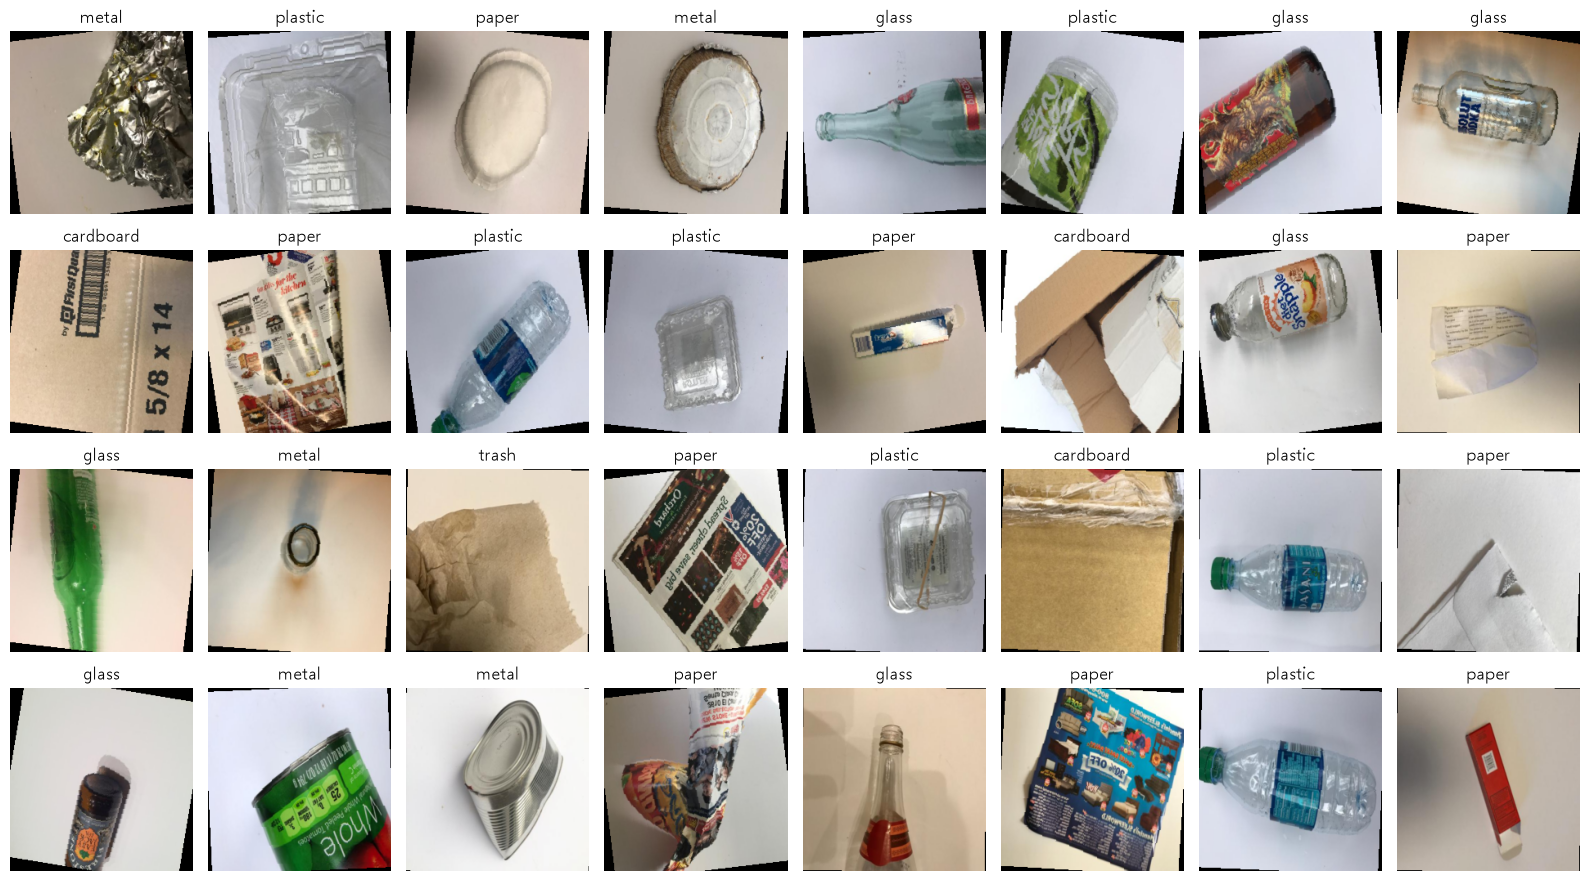

In [17]:
fig, axes = plt.subplots(4, 8, figsize=(16, 9))

# RGB 텐서가 (3, 224, 224)인데 imshow는 (224, 224, 3)으로 채널이 뒤에 있어야하기 때문에 permute를 활용하여 순서를 바꿔준다.
mean_view = torch.tensor(mean).view(3, 1, 1)
std_view = torch.tensor(std).view(3, 1, 1)

for ax, img, label in zip(axes.flatten(), imgs, labels):
    ax.imshow((img * std_view + mean_view).permute(1, 2, 0).clamp(0, 1), cmap="gray")
    ax.set_title(class_dict[label.item()])
    ax.axis("off")

plt.tight_layout()
plt.show()

In [18]:
base_path = r"E:\kdf\machine_learning\resource"
model_weights_path = os.path.join(base_path, "weights")
os.makedirs(model_weights_path, exist_ok=True)

# PyTorch Hub 기본 캐시 경로를 변경
torch.hub.set_dir(model_weights_path)

base_model = models.resnet18(weights="IMAGENET1K_V1").to(device)

In [19]:
for param in base_model.parameters():
    param.requires_grad = False

In [122]:
base_model

ResNet(
  (conv1): Conv2d(3, 64, kernel_size=(7, 7), stride=(2, 2), padding=(3, 3), bias=False)
  (bn1): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
  (relu): ReLU(inplace=True)
  (maxpool): MaxPool2d(kernel_size=3, stride=2, padding=1, dilation=1, ceil_mode=False)
  (layer1): Sequential(
    (0): BasicBlock(
      (conv1): Conv2d(64, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
      (bn1): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
      (relu): ReLU(inplace=True)
      (conv2): Conv2d(64, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
      (bn2): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
    )
    (1): BasicBlock(
      (conv1): Conv2d(64, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
      (bn1): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
      (relu): ReLU(inplace=True)
  

In [20]:
base_model.fc = nn.Sequential(
    nn.Linear(512, 128),
    nn.ReLU(),
    nn.Dropout(0.3, inplace=False),
    nn.Linear(128, 6),
).to(device)

In [21]:
def train_one_epoch_multiclass(model, dataloader, criterion, optimizer, device):
    model.train()
    sum_loss = 0.0
    sum_acc = 0.0

    for i, (X_batch, y_batch) in enumerate(dataloader, 1):
        X_batch = X_batch.to(device)
        y_batch = y_batch.to(device)
        batch_loss = 0.0
        
        optimizer.zero_grad()
        y_pred = model(X_batch)
        loss = criterion(y_pred, y_batch)
        loss.backward()
        optimizer.step()

        batch_loss += loss.item()
        sum_loss += batch_loss

        # 다중 클래스 정확도 계산
        y_pred_index = y_pred.argmax(dim=1)
        acc = (y_batch == y_pred_index).float().mean().item() * 100
        sum_acc += acc

        if i % 20 == 0:
            print(f"[Batch {i}/{len(dataloader)}] | [Batch Loss: {batch_loss:.4f}] | [Batch Accuracy: {acc:.2f}]")

    avg_loss = sum_loss / len(dataloader)
    avg_acc = sum_acc / len(dataloader)

    return avg_loss, avg_acc

In [22]:
@torch.no_grad()
def evaluate_multiclass(model, dataloader, criterion, device):
    model.eval()
    sum_loss = 0.0
    sum_acc = 0.0

    for X_batch, y_batch in dataloader:
        X_batch = X_batch.to(device)
        y_batch = y_batch.to(device)

        y_pred = model(X_batch)
        loss = criterion(y_pred, y_batch)
        sum_loss += loss.item()

        y_pred_index = y_pred.argmax(dim=1)
        acc = (y_batch == y_pred_index).float().mean().item() * 100
        sum_acc += acc

    avg_loss = sum_loss / len(dataloader)
    avg_acc = sum_acc / len(dataloader)

    return avg_loss, avg_acc

In [23]:
def train_model_multiclass(model, model_name, train_loader, val_loader, criterion, optimizer, epochs, device, save_base_dir):
    save_dir = os.path.join(save_base_dir, model_name)
    os.makedirs(save_dir, exist_ok=True)

    history = {
        "train_loss": [], 
        "val_loss": [],
        "train_acc": [],
        "val_acc": []
    }
    best_val_acc = 0.0

    # 학습
    print(f"===================== {model_name} 학습 시작 =====================")
    for epoch in range(epochs):
        lr = optimizer.param_groups[0]["lr"]
        train_loss, train_acc = train_one_epoch_multiclass(model, train_loader, criterion, optimizer, device)
        val_loss, val_acc = evaluate_multiclass(model, val_loader, criterion, device)

        print(f"[Epoch: {epoch + 1}/{epochs}] | Train Loss: {train_loss:.4f} | Train Accuracy: {train_acc:.2f}")
        print(f"[Epoch: {epoch + 1}/{epochs}] | Vaildation Loss: {val_loss:.4f} | Vaildation Accuracy: {val_acc:.2f}")

        history["train_loss"].append(train_loss)
        history["val_loss"].append(val_loss)
        history["train_acc"].append(train_acc)
        history["val_acc"].append(val_acc)

        if val_acc > best_val_acc:
            best_val_acc = val_acc
            torch.save(model.state_dict(), os.path.join(save_dir, "best_model.pth"))

    torch.save(model.state_dict(), os.path.join(save_dir, f"last_model_{epochs}.pth"))
    print(f"===================== {model_name} 학습 종료 =====================")
    return history

In [24]:
criterion = nn.CrossEntropyLoss()
optimizer = optim.Adam(base_model.fc.parameters(), lr=0.001)

In [128]:
history = train_model_multiclass(
    model=base_model,
    model_name="Resnet-Multiclass",
    train_loader=train_dataloader,
    val_loader=val_dataloader,
    criterion=criterion,
    optimizer=optimizer,
    epochs=3,
    device=device,
    save_base_dir=os.path.join(base_path, r"weights")
)

===================== Resnet-Multiclass 학습 시작 =====================
[Batch 20/64] | [Batch Loss: 1.3106] | [Batch Accuracy: 56.25]
[Batch 40/64] | [Batch Loss: 0.8570] | [Batch Accuracy: 78.12]
[Batch 60/64] | [Batch Loss: 1.0263] | [Batch Accuracy: 65.62]
[Epoch: 1/3] | Train Loss: 1.2938 | Train Accuracy: 52.91
[Epoch: 1/3] | Vaildation Loss: 0.9656 | Vaildation Accuracy: 66.29
[Batch 20/64] | [Batch Loss: 0.8554] | [Batch Accuracy: 75.00]
[Batch 40/64] | [Batch Loss: 0.6879] | [Batch Accuracy: 81.25]
[Batch 60/64] | [Batch Loss: 0.9001] | [Batch Accuracy: 68.75]
[Epoch: 2/3] | Train Loss: 0.9038 | Train Accuracy: 67.16
[Epoch: 2/3] | Vaildation Loss: 0.7146 | Vaildation Accuracy: 76.88
[Batch 20/64] | [Batch Loss: 0.7747] | [Batch Accuracy: 68.75]
[Batch 40/64] | [Batch Loss: 0.7406] | [Batch Accuracy: 68.75]
[Batch 60/64] | [Batch Loss: 0.8966] | [Batch Accuracy: 62.50]
[Epoch: 3/3] | Train Loss: 0.7554 | Train Accuracy: 71.33
[Epoch: 3/3] | Vaildation Loss: 0.8276 | Vaildation Acc

In [129]:
base_path

'E:\\kdf\\machine_learning\\resource'

In [25]:
model_name = "Resnet-Multiclass"
best_model_path = os.path.join(base_path, "weights", model_name, "best_model.pth")

# 가중치 없이 best_model만 가져오기
res_model = models.resnet18(weights=None)

res_model.fc = nn.Sequential(
    nn.Linear(512, 128),
    nn.ReLU(),
    nn.Dropout(0.3),
    nn.Linear(128, 6)
)

res_model.load_state_dict(torch.load(best_model_path, map_location=device))
res_model = res_model.to(device)

## 혼동행렬 및 Accuracy 측정

Test Loss: 0.7146  Test Accuracy: 76.88%

              precision    recall  f1-score   support

   cardboard       0.97      0.83      0.89        81
       glass       0.66      0.86      0.74       100
       metal       0.71      0.73      0.72        82
       paper       0.78      0.92      0.84       119
     plastic       0.80      0.63      0.71        97
       trash       0.86      0.22      0.35        27

    accuracy                           0.77       506
   macro avg       0.80      0.70      0.71       506
weighted avg       0.78      0.77      0.76       506



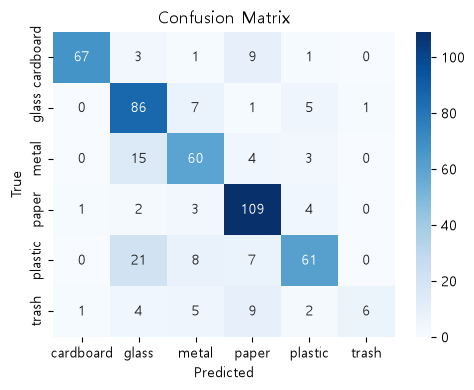

In [131]:
res_model.eval()

y_true = []
y_pred = []
y_prob = []

with torch.no_grad():
    for batch_imgs, batch_labels in val_dataloader:
        outputs = res_model(batch_imgs.to(device))
        probs = F.softmax(outputs, dim=1)
        _, batch_preds = outputs.max(1)
        y_pred.extend(batch_preds.cpu().tolist())
        y_true.extend(batch_labels.tolist())
        y_prob.append(probs.cpu())

val_loss, val_acc = evaluate_multiclass(res_model, val_dataloader, criterion, device)
print(f"Test Loss: {val_loss:.4f}  Test Accuracy: {val_acc:.2f}%\n")

target_names = [class_dict[i] for i in range(len(class_dict))]
print(classification_report(y_true, y_pred, target_names=target_names))

cm = confusion_matrix(y_true, y_pred)

plt.figure(figsize=(5, 4))
sns.heatmap(cm, annot=True, fmt="d", cmap="Blues", xticklabels=target_names, yticklabels=target_names)
plt.xlabel("Predicted")
plt.ylabel("True")
plt.title("Confusion Matrix")

plt.tight_layout()
plt.show()

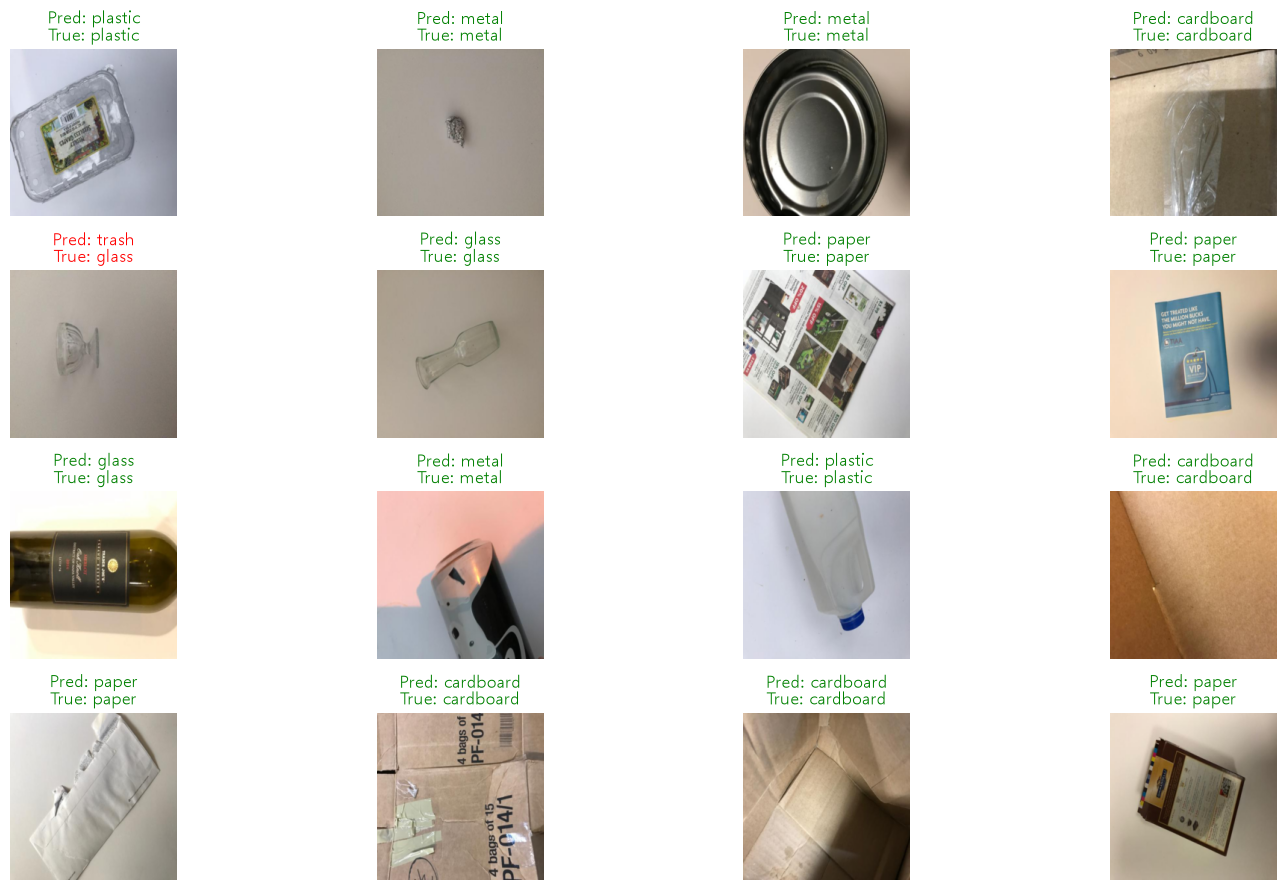

In [132]:
res_model.eval()

imgs, labels = next(iter(val_dataloader))
imgs_dev = imgs.to(device)

with torch.no_grad():
    outputs = res_model(imgs_dev)
    _, preds = outputs.max(1) 

img_list_cpu = imgs.cpu()
y_pred_list_cpu = preds.cpu()
y_true_list_cpu = labels.cpu()

# 시각화
fig, axes = plt.subplots(4, 4, figsize=(16, 9))

for ax, img, y_pred, y_true in zip(axes.flatten(), img_list_cpu, y_pred_list_cpu, y_true_list_cpu):
    ax.imshow((img * std_view + mean_view).permute(1, 2, 0).clamp(0, 1), cmap="gray", vmin=0, vmax=1)
    pred_label = class_dict[y_pred.item()]
    true_label = class_dict[y_true.item()]
    color = "green" if pred_label == true_label else "red"
    ax.axis("off")
    ax.set_title(f"Pred: {pred_label}\nTrue: {true_label}", color=color)

plt.tight_layout()   
plt.show()

## 오분류 중 예측 확률이 가장 높았던 10가지

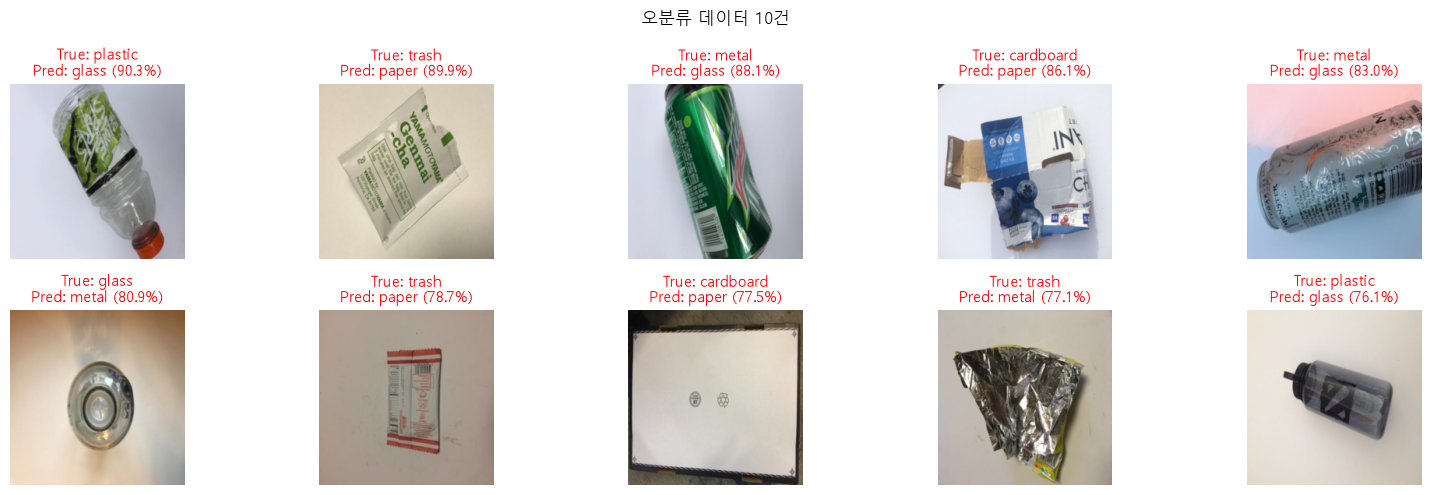

In [133]:
res_model.eval()

incorrect_samples = []

with torch.no_grad():
    for batch_imgs, batch_labels in val_dataloader:
        outputs = res_model(batch_imgs.to(device))
        probs = F.softmax(outputs, dim=1)
        preds = probs.argmax(dim=1)

        for img, true_l, pred_l, prob in zip(batch_imgs, batch_labels, preds.cpu(), probs.cpu()):
            if true_l != pred_l:
                incorrect_samples.append({
                    "img": img,
                    "true_label": int(true_l),
                    "pred_label": int(pred_l),
                    "prob": float(prob[pred_l]),        
                    "true_prob": float(prob[true_l]),   
                })

incorrect_samples.sort(key=lambda s: s["prob"], reverse=True)

num = min(10, len(incorrect_samples))
cols = 5
rows = (num + cols - 1) // cols

fig, axes = plt.subplots(rows, cols, figsize=(16, 5))
axes = np.atleast_1d(axes).flatten()

for ax, sample in zip(axes, incorrect_samples[:num]):
    img = sample["img"].cpu()
    ax.imshow((img * std_view + mean_view).permute(1, 2, 0).clamp(0, 1))

    true_name = class_dict[int(sample["true_label"])]
    pred_name = class_dict[int(sample["pred_label"])]

    title = f"True: {true_name}\nPred: {pred_name}"
    if "prob" in sample:                       
        title += f" ({float(sample['prob']) * 100:.1f}%)"

    ax.set_title(title, color="red", fontsize=11)
    ax.axis("off")

for ax in axes[num:]:                            
    ax.axis("off")

plt.suptitle(f"오분류 데이터 {num}건")
plt.tight_layout()
plt.show()

In [139]:
rows = []
for k, s in enumerate(incorrect_samples[:10], 1):
    rows.append({
        "No": k,
        "정답 라벨": class_dict[s["true_label"]],
        "예측 라벨": class_dict[s["pred_label"]],
        "예측 확률": f"{s['prob'] * 100:.1f}%",
        "정답 확률": f"{s['true_prob'] * 100:.1f}%",
    })

wrong_df = pd.DataFrame(rows)
wrong_df

,No,정답 라벨,예측 라벨,예측 확률,정답 확률
0,1,plastic,glass,90.3%,8.3%
1,2,trash,paper,89.9%,1.2%
2,3,metal,glass,88.1%,5.4%
3,4,cardboard,paper,86.1%,4.2%
4,5,metal,glass,83.0%,8.8%
5,6,glass,metal,80.9%,15.7%
6,7,trash,paper,78.7%,7.6%
7,8,cardboard,paper,77.5%,14.6%
8,9,trash,metal,77.1%,5.5%
9,10,plastic,glass,76.1%,8.8%


## Grad-CAM

In [50]:
def collect_samples(model, dataloader, device, n_correct=3, n_wrong=2, diverse=True):
    """검증셋 전체를 돌며 정분류/오분류를 확신도 순으로 모아 n_correct + n_wrong장을 반환한다."""
    model.eval()
    correct_samples, incorrect_samples = [], []

    with torch.no_grad():
        for imgs, labels in dataloader:
            imgs_device = imgs.to(device)
            probs = F.softmax(model(imgs_device), dim=1).cpu()
            pred_labels = probs.argmax(dim=1)

            correct_mask = (pred_labels == labels)
            incorrect_mask = ~correct_mask

            for mask, bucket in ((correct_mask, correct_samples),
                                 (incorrect_mask, incorrect_samples)):
                if mask.any():
                    for img, label, pred, prob in zip(imgs[mask], labels[mask],
                                                      pred_labels[mask], probs[mask]):
                        bucket.append({
                            "img": img,                           # 정규화된 텐서 (3, 224, 224)
                            "true_label": label.item(),
                            "pred_label": pred.item(),
                            "prob": prob[pred].item(),            # 예측 라벨의 확률 = 확신도
                            "true_prob": prob[label].item(),      # 정답 라벨에 준 확률
                        })

    print(f"전체 정분류 {len(correct_samples)}건 / 오분류 {len(incorrect_samples)}건")

    correct_samples.sort(key=lambda s: s["prob"], reverse=True)
    incorrect_samples.sort(key=lambda s: s["prob"], reverse=True)

    # 정분류는 클래스가 겹치지 않게 뽑는다 (같은 재질 3장이면 관찰 내용이 단조로워짐)
    if diverse:
        seen, picked = set(), []
        for s in correct_samples:
            if s["true_label"] not in seen:
                seen.add(s["true_label"])
                picked.append(s)
            if len(picked) == n_correct:
                break
        correct_samples = picked

    selected = correct_samples[:n_correct] + incorrect_samples[:n_wrong]
    print(f"선별: 정분류 {min(n_correct, len(correct_samples))}장 + "
          f"오분류 {min(n_wrong, len(incorrect_samples))}장 = {len(selected)}장\n")
    return selected


samples = collect_samples(res_model, val_dataloader, device, n_correct=3, n_wrong=2)

전체 정분류 389건 / 오분류 117건
선별: 정분류 3장 + 오분류 2장 = 5장



In [51]:
store = {"act": None, "grad": None}

def forward_hook(module, inp, out):
    store["act"] = out.detach()

def backward_hook(module, grad_in, grad_out):
    store["grad"] = grad_out[0].detach()

# 동결 상태면 역전파가 타겟 층에 도달하지 못해 grad가 None으로 남는다.
# 가중치를 갱신하는 게 아니라 기울기 '경로'만 여는 것이므로 파인튜닝이 아니다.
for p in res_model.parameters():
    p.requires_grad_(True)

# BasicBlock은 forward에서 in-place 연산(out += identity, ReLU(inplace=True))을 쓰므로
# full_backward_hook이 깨진다. in-place가 없는 마지막 Conv2d를 타겟으로 잡는다.
conv_layers = [m for m in res_model.modules() if isinstance(m, nn.Conv2d)]
target_layer = conv_layers[-1]          # layer4[1].conv2, Conv2d(512, 512)
print(f"타겟 레이어: {target_layer}\n")

h_fwd = target_layer.register_forward_hook(forward_hook)
h_bwd = target_layer.register_full_backward_hook(backward_hook)

# 히트맵을 생성해주는 함수
def make_gradcam(model, img_tensor, device):
    input_tensor = img_tensor.unsqueeze(0).to(device)    # (C,H,W) -> (1,C,H,W)

    model.zero_grad()
    output = model(input_tensor)                         # no_grad 쓰면 안 됨 (역전파 필요)
    probs = F.softmax(output, dim=1)[0]
    pred_idx = int(probs.argmax())

    output[0, pred_idx].backward()                       # 예측 클래스 점수만 역전파
    assert store["grad"] is not None, "훅이 호출되지 않았습니다. target_layer를 확인하세요."

    pooled = torch.mean(store["grad"], dim=[0, 2, 3])            # (C,) 채널별 중요도
    weighted = store["act"][0] * pooled[:, None, None]           # (C, H, W)
    heatmap = torch.mean(weighted, dim=0).cpu().numpy()          # (7, 7)

    heatmap = np.maximum(heatmap, 0)                             # ReLU: 양수 기여만
    if heatmap.max() != 0:
        heatmap /= heatmap.max()
    return heatmap, probs, pred_idx

# 히트맵이 어디를 중점으로 수치화했는지 집중도를 수치화하는 함수
def describe_focus(heatmap):
    H, W = heatmap.shape
    total = heatmap.sum()

    pr, pc = np.unravel_index(heatmap.argmax(), heatmap.shape)   # 최고 집중 지점
    v = ["상단", "중앙", "하단"][min(int(pr / H * 3), 2)]
    h = ["좌측", "중앙", "우측"][min(int(pc / W * 3), 2)]

    c0, c1 = H // 2 - 1, H // 2 + 2
    center = heatmap[c0:c1, c0:c1].sum() / total * 100
    mask = np.ones_like(heatmap, dtype=bool)
    mask[1:H - 1, 1:W - 1] = False
    border = heatmap[mask].sum() / total * 100

    # 균일하게 퍼졌을 때의 기준값(면적 비율). 이걸 넘어야 '집중'이라 할 수 있다.
    center_base = 9 / (H * W) * 100                              # 7x7이면 18.4%
    border_base = (H * W - (H - 2) * (W - 2)) / (H * W) * 100    # 7x7이면 49.0%

    c_ratio, b_ratio = center / center_base, border / border_base
    if c_ratio >= 1.5:
        verdict = "물체 중앙에 집중"
    elif b_ratio >= 1.3:
        verdict = "가장자리·배경 편향 의심"
    else:
        verdict = "특정 지점 없이 전반에 분산"

    return {"pos": f"{v} {h}", "grid": (int(pr), int(pc)),
            "center": center, "center_x": c_ratio,
            "border": border, "border_x": b_ratio,
            "verdict": verdict,
            "base": (center_base, border_base)}

타겟 레이어: Conv2d(512, 512, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)



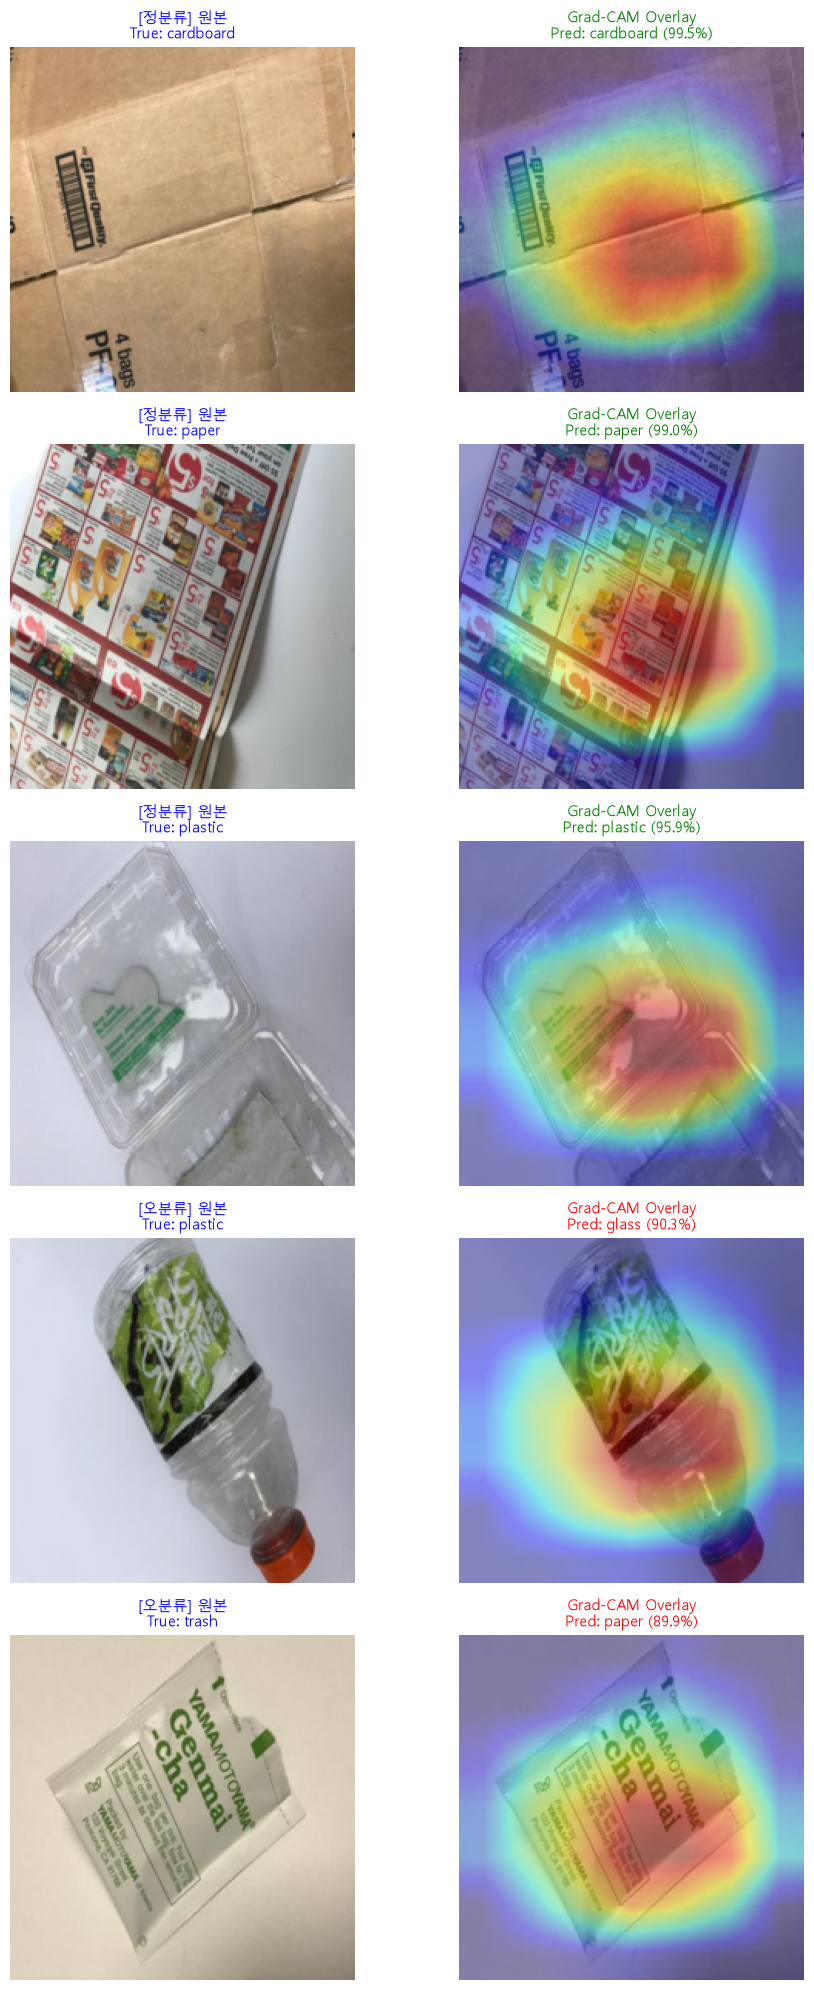

In [71]:
mean_view = torch.tensor(mean).view(3, 1, 1)
std_view = torch.tensor(std).view(3, 1, 1)

focus_rows = []     # 분석 수치는 출력하지 않고 모아만 둔다
heatmaps = []       # 셀 5에서 재사용

fig, axes = plt.subplots(len(samples), 2, figsize=(10, 4 * len(samples)))

for row, sample in enumerate(samples):
    heatmap, probs, pred_idx = make_gradcam(res_model, sample["img"], device)
    focus = describe_focus(heatmap)
    heatmaps.append(heatmap)

    true_name = class_dict[sample["true_label"]]
    pred_name = class_dict[pred_idx]
    is_correct = (pred_idx == sample["true_label"])
    mark, color = ("정분류", "green") if is_correct else ("오분류", "red")

    # 역정규화해야 색이 제대로 나온다
    disp = (sample["img"] * std_view + mean_view).permute(1, 2, 0).clamp(0, 1).numpy()

    # 7x7 히트맵을 원본 크기로 확대 (원 해상도가 7x7이라 뭉개져 보이는 게 정상)
    heat_img = Image.fromarray(np.uint8(255 * heatmap)).resize(
        (disp.shape[1], disp.shape[0]), Image.Resampling.BILINEAR)

    axes[row, 0].imshow(disp)
    axes[row, 0].set_title(f"[{mark}] 원본\nTrue: {true_name}", fontsize=11, color="blue")
    axes[row, 0].axis("off")

    axes[row, 1].imshow(disp)
    axes[row, 1].imshow(heat_img, cmap="jet", alpha=0.4)      # 빨강=집중, 파랑=무시
    axes[row, 1].set_title(f"Grad-CAM Overlay\nPred: {pred_name} "
                           f"({float(probs[pred_idx]) * 100:.1f}%)", fontsize=11, color=color)
    axes[row, 1].axis("off")

    focus_rows.append({
        "Num": row + 1,
        "구분": mark,
        "정답": true_name,
        "예측": pred_name,
        "예측 확률": f"{float(probs[pred_idx]) * 100:.1f}%",
        "정답 확률": f"{float(probs[sample['true_label']]) * 100:.1f}%",
        "집중지역": focus["pos"],
        "격자": str(focus["grid"]),
        "중앙 집중도": f"{focus['center']:.1f}% ({focus['center_x']:.2f}배)",
        "테두리 비중": f"{focus['border']:.1f}% ({focus['border_x']:.2f}배)",
        "판정": focus["verdict"],
    })
    focus_df = pd.DataFrame(focus_rows)

plt.tight_layout()
plt.show()

In [67]:
focus_df

,Num,구분,정답,예측,예측 확률,정답 확률,최고 집중,격자,중앙 집중도,테두리 비중,판정
0,1,정분류,cardboard,cardboard,99.5%,99.5%,중앙 중앙,"(4, 4)",44.8% (2.44배),9.3% (0.19배),물체 중앙에 집중
1,2,정분류,paper,paper,99.0%,99.0%,중앙 중앙,"(4, 4)",44.8% (2.44배),9.3% (0.19배),물체 중앙에 집중
2,3,정분류,plastic,plastic,95.9%,95.9%,중앙 중앙,"(4, 4)",44.8% (2.44배),9.3% (0.19배),물체 중앙에 집중
3,4,오분류,plastic,glass,90.3%,8.3%,중앙 중앙,"(4, 4)",44.8% (2.44배),9.3% (0.19배),물체 중앙에 집중
4,5,오분류,trash,paper,89.9%,1.2%,중앙 중앙,"(4, 4)",44.8% (2.44배),9.3% (0.19배),물체 중앙에 집중


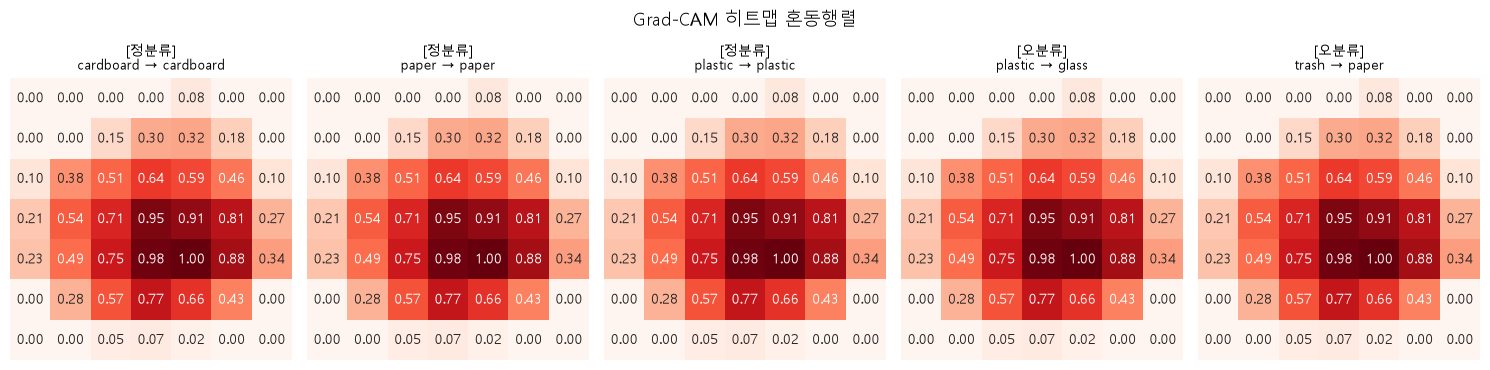

In [73]:
fig, axes = plt.subplots(1, len(heatmaps), figsize=(3 * len(heatmaps), 4))
axes = np.atleast_1d(axes)

for ax, hm, info in zip(axes, heatmaps, focus_rows):
    sns.heatmap(hm, annot=True, fmt=".2f", cmap="Reds", cbar=False,
                square=True, ax=ax)
    ax.set_title(f"[{info['구분']}]\n{info['정답']} → {info['예측']}", fontsize=10)
    ax.set_xticks([])
    ax.set_yticks([])

plt.suptitle("Grad-CAM 히트맵 혼동행렬", fontsize=13)
plt.tight_layout()
plt.show()

h_fwd.remove()
h_bwd.remove()